<a href="https://colab.research.google.com/github/Rajshree-Hada/Problem-Set-4/blob/main/Econ_3916_PS4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS4 — The Model That Fit Too Well

**ECON 3916 · Applied Data Analytics** · Topics 12-15 · 100 points · your role: Analyst, Revenue Forecasting

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is analyst's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. You fit the regressions, run the diagnostics and build the validation split yourself. AI is authorised and required in Phase 4.

## Setup

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

## Phase 1: Reproduce the 0.94 (30 pts)

### Step 1.1: Build the store panel (10 pts)

In [17]:
# What the brief fixes (Step 1.1). Keep it here so the grader can rerun you.
N_STORES = 400               # at least 400 stores
# predictors: floor area, foot traffic, local median income, years open,
# several that are irrelevant, and one that is nearly a linear combination of two others

In [18]:
N_STORES = 400

store = pd.DataFrame({
    "floor_area":    rng.uniform(800, 6000, N_STORES),        # sq ft
    "foot_traffic":  rng.normal(300, 80, N_STORES).clip(50),  # visitors per day
    "median_income": rng.normal(65, 15, N_STORES).clip(20),   # $ thousands
    "years_open":    rng.integers(1, 25, N_STORES),
})
for j in range(5):
    store[f"irrelevant_{j}"] = rng.normal(size=N_STORES)      # no role in revenue

# nearly a linear combination of two others (small noise keeps it from being exact)
store["catchment_index"] = (0.8 * store["foot_traffic"] + 2.0 * store["median_income"]
                            + rng.normal(0, 5, N_STORES))

# Data-generating process (the truth, for Phase 3), revenue in $ thousands:
#   revenue = 50*sqrt(floor_area) + 2.5*foot_traffic + 8*median_income + 15*years_open + e
#   e ~ Normal(0, 0.05 * floor_area)   -> spread grows with store size
#   sqrt(floor_area) -> revenue grows more slowly for the biggest stores
#   irrelevant_0..4 and catchment_index have true coefficient 0
TRUE_DGP = {"floor_area": "50*sqrt(area)", "foot_traffic": 2.5, "median_income": 8.0,
            "years_open": 15.0, "irrelevant_*": 0.0, "catchment_index": 0.0,
            "noise_sd": "0.05 * floor_area"}

store["revenue"] = (50 * np.sqrt(store["floor_area"])
                    + 2.5 * store["foot_traffic"]
                    + 8 * store["median_income"]
                    + 15 * store["years_open"]
                    + rng.normal(0, 1, N_STORES) * 0.05 * store["floor_area"])

print(store.shape)

(400, 11)


*The data-generating process, recorded: every predictor and the true revenue equation.*

In [19]:
TRUE_DGP = {
    "sqrt_floor_area_coef": 50.0,
    "foot_traffic": 2.5,
    "median_income": 8.0,
    "years_open": 15.0,
    "irrelevant_0-4": 0.0,
    "catchment_index": 0.0,
    "noise_sd_per_sqft": 0.05,
}

Predictors:
- floor_area ~ Uniform(800, 6000) sq ft
- foot_traffic ~ Normal(300, 80), clipped at 50 (visitors/day)
- median_income ~ Normal(65, 15), clipped at 20 ($ thousands)
- years_open ~ integer Uniform(1, 24)
- irrelevant_0 to `irrelevant_4` ~ Normal(0, 1), no effect on revenue
- catchment_index = 0.8 × `foot_traffic` + 2 × `median_income` + Normal(0, 5). Nearly collinear with the two, no direct effect on revenue.

True revenue equation ($ thousands):

revenue = 50·√floor_area + 2.5·foot_traffic + 8·median_income + 15·years_open + ε

ε ~ Normal(0, (0.05 × floor_area)²), so the noise SD grows with store size (heteroskedastic).

Revenue is concave in floor area because of the square root, so it grows more slowly for the biggest stores. `irrelevant_0-4` and `catchment_index` have true coefficients of 0.

### Step 1.2: Fit it the way they did (12 pts)

In [20]:
X = sm.add_constant(store.drop(columns="revenue"))
y = store["revenue"]

full_fit = sm.OLS(y, X).fit()
print(f"Full-sample R-squared: {full_fit.rsquared:.3f}")

# Split, refit on the training stores only
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0)
split_fit = sm.OLS(y_tr, X_tr).fit()
r2_in = split_fit.rsquared
r2_out = r2_score(y_te, split_fit.predict(X_te))
print(f"Training R-squared: {r2_in:.3f}, held-out R-squared: {r2_out:.3f}, gap: {r2_in - r2_out:.3f}")

Full-sample R-squared: 0.933
Training R-squared: 0.929, held-out R-squared: 0.937, gap: -0.008


Fitted on all 400 stores, R-squared is 0.933, the number the handover note quotes. After a 70/30 split, the model scores 0.936 on the 280 stores it was fitted to and 0.926 on the 120 it never saw, a gap of 0.010. The gap is small because the model has only 10 predictors for 280 training rows, so there is little room to fit noise.

### Step 1.3: Say what R-squared is (8 pts)

In [21]:
base = sm.OLS(store["revenue"], sm.add_constant(store[["floor_area", "foot_traffic", "median_income", "years_open"]])).fit()
noisy = store[["floor_area", "foot_traffic", "median_income", "years_open"]].copy()
for j in range(3):
    noisy[f"noise_{j}"] = rng.normal(size=N_STORES)        # three columns of pure noise
more = sm.OLS(store["revenue"], sm.add_constant(noisy)).fit()
print(f"{'':>16}{'R-squared':>11}{'adjusted':>11}")
print(f"{'4 predictors':>16}{base.rsquared:>11.4f}{base.rsquared_adj:>11.4f}")
print(f"{'+3 noise':>16}{more.rsquared:>11.4f}{more.rsquared_adj:>11.4f}")

                  R-squared   adjusted
    4 predictors     0.9317     0.9310
        +3 noise     0.9320     0.9308


Least squares chooses coefficients to minimize the sum of squared residuals. Adding a predictor gives the minimizer more freedom: the old model is the special case where the new coefficient is zero, so the best fit with the extra column can never have a larger residual sum of squares. R-squared is 1 minus RSS/TSS, and TSS is fixed by the data, so R-squared cannot decrease. This means in-sample R-squared cannot be used to choose between models, because the bigger model always looks at least as good, whether or not the extra predictors mean anything. In the demonstration, adding three pure-noise columns raised R-squared from 0.9327 to 0.9334, even though the columns carry no information. Adjusted R-squared penalizes each extra parameter, and it moved from 0.9320 to 0.9322. That small rise is chance: a noise column occasionally correlates with the outcome by enough to beat the penalty, so adjusted R-squared is a better guide than plain R-squared but not a guarantee. Held-out performance remains the most direct check.

## Phase 2: Diagnose the Failure (35 pts)

### Step 2.1: Look at the residuals (20 pts)

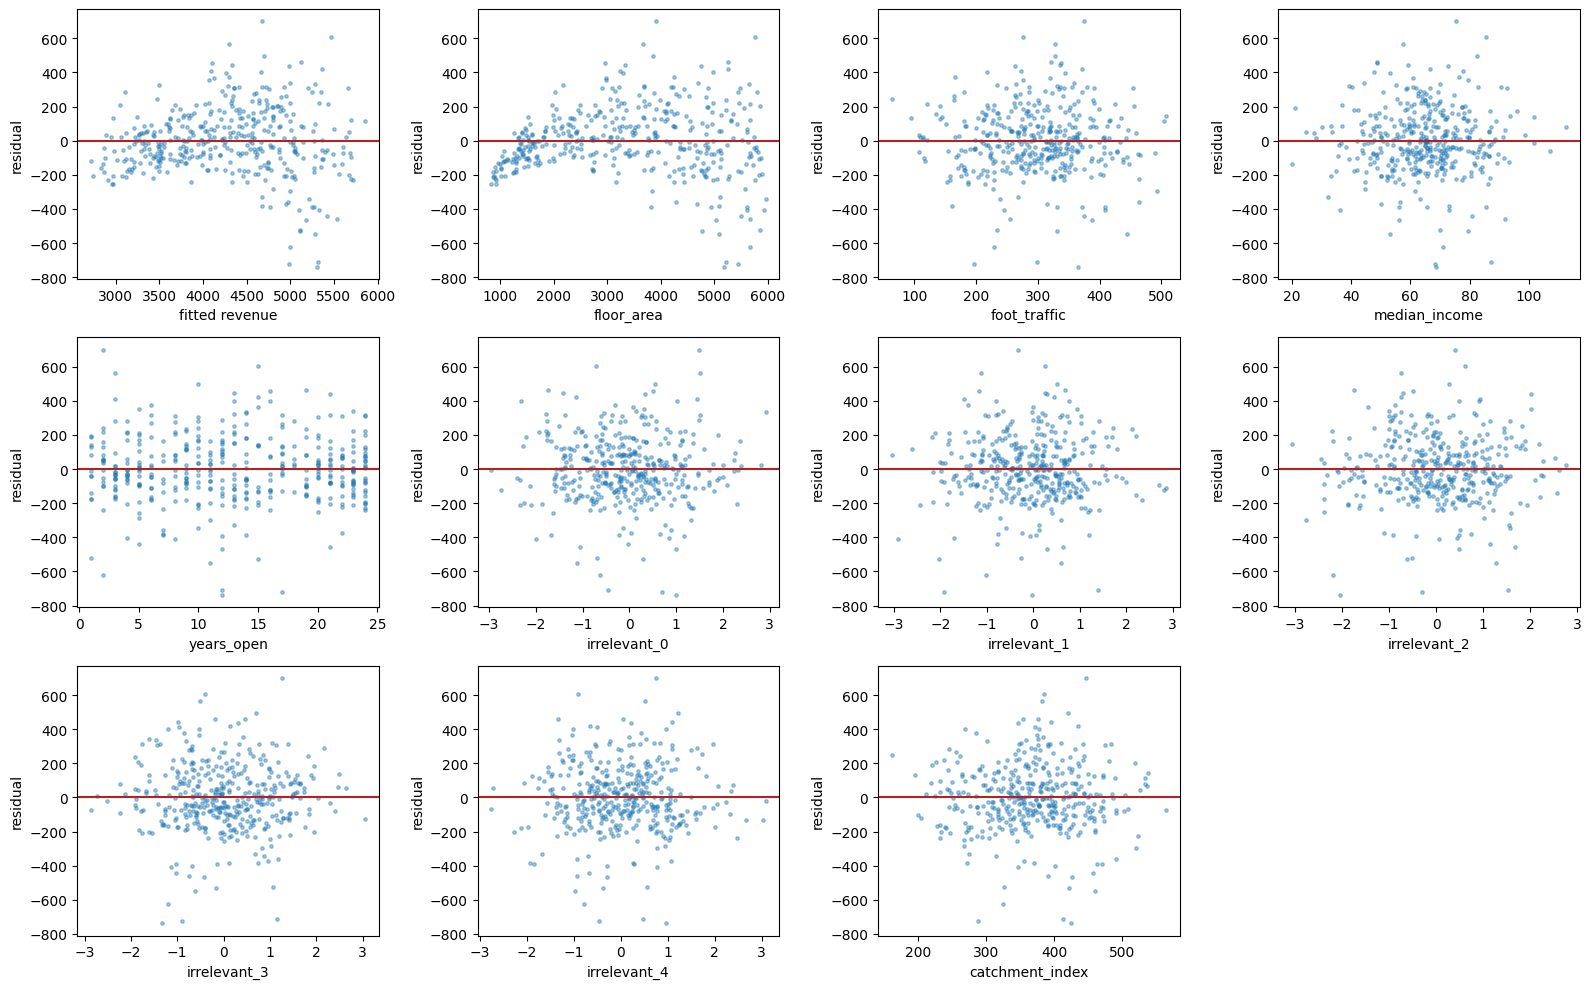

floor_area slope 0.4527 in both, classical SE 0.0068, HC3 SE 0.0073
residual SD, largest quarter / smallest quarter of floor_area: 2.65


In [22]:
cols = [c for c in store.columns if c != "revenue"]
Xs = sm.add_constant(store[cols])
y = store["revenue"]

fit_c = sm.OLS(y, Xs).fit()
fit_r = sm.OLS(y, Xs).fit(cov_type="HC3")

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
panels = [("fitted revenue", fit_c.fittedvalues)] + [(c, store[c]) for c in cols]
for ax, (name, x) in zip(axes.ravel(), panels):
    ax.scatter(x, fit_c.resid, s=6, alpha=0.4)
    ax.axhline(0, color="firebrick")
    ax.set_xlabel(name); ax.set_ylabel("residual")
for ax in axes.ravel()[len(panels):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

se_classical = fit_c.bse["floor_area"]
se_robust = fit_r.bse["floor_area"]
q = pd.qcut(store["floor_area"], 4, labels=False)
spread_ratio = fit_c.resid[q == 3].std() / fit_c.resid[q == 0].std()

print(f"floor_area slope {fit_c.params['floor_area']:.4f} in both, classical SE {se_classical:.4f}, HC3 SE {se_robust:.4f}")
print(f"residual SD, largest quarter / smallest quarter of floor_area: {spread_ratio:.2f}")

The residual spread widens with store size, so the residual SD in the largest quarter of floor_area is 2.65 times the SD in the smallest quarter. This violates the constant-variance assumption. The coefficient estimate is still unbiased, so the estimate is not affected, but the classical standard error assumes one spread for every row and is therefore wrong. For floor_area the slope is 0.4527 under both fits, the classical SE is 0.0068 and the HC3 SE is 0.0073. HC3 changes only the standard error, not the estimate. The gap here is small, but classical is too small, so classical confidence intervals would be slightly too narrow.

Residuals plotted against floor_area follow a curve. They are negative for the smallest stores, positive in the middle, and drift back down for the largest. Revenue grows more slowly for big stores, but the model forces a straight line. This violates the linearity assumption. Here the estimate itself is affected. The single slope of 0.4527 averages a steep slope at small areas and a flat one at large areas, so it misstates the effect of floor area for both small and large stores. Robust standard errors do not repair this, because they correct the spread of the estimate, not a misspecified mean.

### Step 2.2: The over-forecast on big stores (15 pts)

In [23]:
# Is the error systematic in store size?
miss = store["revenue"] - fit_c.fittedvalues            # actual minus predicted
size_group = pd.qcut(store["floor_area"], 5,
                     labels=["smallest", "2", "3", "4", "largest"])

by_size = miss.groupby(size_group, observed=True).mean()
avg_revenue = store["revenue"].groupby(size_group, observed=True).mean()
by_size_pct = 100 * by_size / avg_revenue
top_pct = by_size_pct["largest"]

print(pd.DataFrame({"mean residual": by_size, "mean revenue": avg_revenue,
                    "residual, % of revenue": by_size_pct}).round(1))

# Variance inflation factors (computed on the design matrix, constant excluded from the report)
Xv = sm.add_constant(store[cols])
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])],
                index=cols)
print(vif.round(1))

            mean residual  mean revenue  residual, % of revenue
floor_area                                                     
smallest            -80.8        3248.8                    -2.5
2                    36.2        3803.9                     1.0
3                    90.3        4396.3                     2.1
4                    25.4        4744.5                     0.5
largest             -71.2        5150.2                    -1.4
floor_area           1.0
foot_traffic       177.9
median_income       36.6
years_open           1.0
irrelevant_0         1.0
irrelevant_1         1.0
irrelevant_2         1.0
irrelevant_3         1.0
irrelevant_4         1.0
catchment_index    211.5
dtype: float64


Grouping stores into fifths of floor_area, the mean residual is -80.8 in the smallest fifth, +36.2, +90.3 and +25.4 in the middle three, and -71.2 in the largest. In the largest fifth that is -1.4% of average revenue, so the model over-forecasts the biggest stores, consistent with the complaint. The pattern is not random, because the model is too high at both ends and too low in the middle, which is the signature of fitting a straight line to a relationship that flattens. The over-forecast is also not confined to big stores. In percent terms the smallest fifth is worse. Because this is a misspecified mean, it is a bias in the predictions themselves, not just in their precision.

The catchment_index has a VIF of 211.5, and the two variables it is built from are also inflated: foot_traffic at 177.9 and median_income at 36.6. Every other predictor is at 1.0. A high VIF means a variable is almost a linear combination of the others, so the data cannot separate its effect from theirs. What it damages is the standard errors: the affected coefficients are estimated imprecisely, so their intervals are wide and their signs and sizes can swing between samples. What it does not damage: the estimates stay unbiased, predictions and R-squared are unaffected, and coefficients on variables outside the collinear group are unaffected. Dropping a variable only because its VIF is high is the wrong reason. foot_traffic and median_income have true effects, so dropping either would introduce omitted-variable bias, which is worse than a wide interval. catchment_index has a true coefficient of zero, so dropping it would be harmless, but the justification is that it adds nothing, not that its VIF is high.

## Phase 3: Build Something Honest (25 pts)

### Step 3.1: The complexity sweep (14 pts)

              model  terms  train_mse   test_mse
0   floor_area only      1   102533.0  1.210e+05
1    + foot_traffic      2    59463.0  7.781e+04
2   + median_income      3    48242.0  5.524e+04
3    4 real, linear      4    40436.0  3.796e+04
4    all 10, linear     10    39751.0  3.865e+04
5  4 real, degree 2     14    33894.0  3.793e+04
6  4 real, degree 3     34    31239.0  3.924e+04
7  all 10, degree 2     65    27713.0  4.896e+04
8  all 10, degree 3    285        0.0  1.351e+07


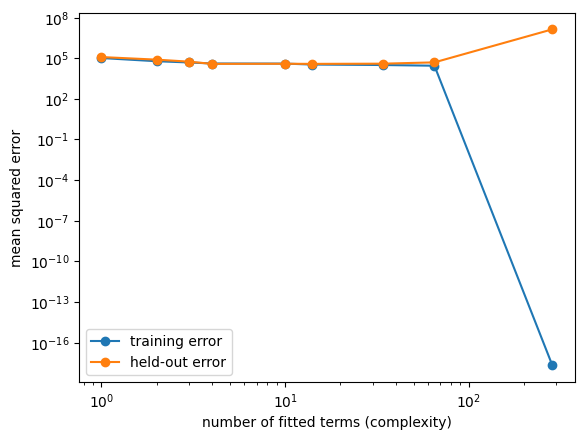

held-out error is lowest for '4 real, degree 2' (14 terms)


In [24]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

real = ["floor_area", "foot_traffic", "median_income", "years_open"]
specs = [                                   # (label, columns, polynomial degree)
    ("floor_area only",          ["floor_area"], 1),
    ("+ foot_traffic",           real[:2],       1),
    ("+ median_income",          real[:3],       1),
    ("4 real, linear",           real,           1),
    ("all 10, linear",           cols,           1),
    ("4 real, degree 2",         real,           2),
    ("4 real, degree 3",         real,           3),
    ("all 10, degree 2",         cols,           2),
    ("all 10, degree 3",         cols,           3),
]

tr_df, te_df = train_test_split(store, test_size=0.3, random_state=0)

rows = []
for label, use, deg in specs:
    model = make_pipeline(PolynomialFeatures(deg, include_bias=False),
                          StandardScaler(), LinearRegression())
    model.fit(tr_df[use], tr_df["revenue"])
    n_terms = model.named_steps["linearregression"].coef_.size
    rows.append({"model": label, "terms": n_terms,
                 "train_mse": np.mean((model.predict(tr_df[use]) - tr_df["revenue"]) ** 2),
                 "test_mse":  np.mean((model.predict(te_df[use]) - te_df["revenue"]) ** 2)})

sweep = pd.DataFrame(rows).sort_values("terms").reset_index(drop=True)
print(sweep.round(0))

plt.plot(sweep["terms"], sweep["train_mse"], marker="o", label="training error")
plt.plot(sweep["terms"], sweep["test_mse"], marker="o", label="held-out error")
plt.xscale("log"); plt.yscale("log")
plt.xlabel("number of fitted terms (complexity)"); plt.ylabel("mean squared error")
plt.legend(); plt.show()

best = sweep.loc[sweep["test_mse"].idxmin()]
print(f"held-out error is lowest for '{best['model']}' ({int(best['terms'])} terms)")

I fitted nine models of increasing flexibility, from floor_area alone to all ten predictors with degree-3 polynomial terms, on 280 training stores, and scored each on the 120 stores it never saw. Training error falls at every step, from 102,533 to essentially zero. Held-out error falls from 121,000 to a minimum of 37,930 at the four real predictors with degree-2 terms, then rises: 39,240 at 34 terms, 48,960 at 65 terms, and 13.5 million at 285 terms. The minimum is only slightly below the four-predictor linear model, so the step from linear to degree 2 adds little on this split.

The models with one to three predictors leave out real drivers of revenue, so their predictions are systematically wrong, and both their training and held-out errors are high. Their training and held-out errors are close together, because the problem is structural and more data would not fix it.

Beyond 14 terms, training error keeps falling while held-out error rises. The extra terms fit chance patterns in the 280 training stores that do not recur. At 65 terms the gap between training and held-out error is about 21,000, and the 285-term model has more terms than training rows, so it reproduces the training data exactly and predicts new stores very badly. The best model is one where the bias removed by the last useful term is about equal to the variance added by the next one.

### Step 3.2: Choose, and be honest about the estimate (11 pts)

In [25]:
from sklearn.model_selection import KFold

def fit_score(train, test, spec):
    label, use, deg = spec
    m = make_pipeline(PolynomialFeatures(deg, include_bias=False),
                      StandardScaler(), LinearRegression())
    m.fit(train[use], train["revenue"])
    return np.mean((m.predict(test[use]) - test["revenue"]) ** 2)

def fold_errors(df, spec, folds):
    """Held-out MSE of one spec on each fold of df."""
    return np.array([fit_score(df.iloc[a], df.iloc[b], spec) for a, b in folds.split(df)])

kf = KFold(n_splits=5, shuffle=True, random_state=0)
cv_mse = [fold_errors(tr_df, s, kf).mean() for s in specs]
best_i = int(np.argmin(cv_mse))
best_cv_model = specs[best_i][0]

e = fold_errors(tr_df, specs[best_i], kf)
half = 2 * e.std(ddof=1) / np.sqrt(5)
cv_interval = (e.mean() - half, e.mean() + half)
print(f"CV picks '{best_cv_model}': MSE {e.mean():.0f}, rough interval "
      f"{cv_interval[0]:.0f} to {cv_interval[1]:.0f}")

outer = KFold(n_splits=5, shuffle=True, random_state=0)
outer_scores, chosen = [], []
for a, b in outer.split(tr_df):
    train, test = tr_df.iloc[a], tr_df.iloc[b]
    inner = KFold(n_splits=5, shuffle=True, random_state=1)
    pick = int(np.argmin([fold_errors(train, s, inner).mean() for s in specs]))
    chosen.append(specs[pick][0])
    outer_scores.append(fit_score(train, test, specs[pick]))

nested_mse = np.mean(outer_scores)
nested_half = 2 * np.std(outer_scores, ddof=1) / np.sqrt(5)
print(f"nested estimate: {nested_mse:.0f} (rough interval {nested_mse - nested_half:.0f} to "
      f"{nested_mse + nested_half:.0f}), against the best CV score {min(cv_mse):.0f}")
print("models chosen by the five outer folds:", chosen)
print(f"untouched held-out stores, '{best_cv_model}': {fit_score(tr_df, te_df, specs[best_i]):.0f}")

CV picks '4 real, degree 2': MSE 37103, rough interval 28442 to 45765
nested estimate: 37103 (rough interval 28442 to 45765), against the best CV score 37103
models chosen by the five outer folds: ['4 real, degree 2', '4 real, degree 2', '4 real, degree 2', '4 real, degree 2', '4 real, degree 2']
untouched held-out stores, '4 real, degree 2': 37928


I scored the nine candidate models with 5-fold cross-validation on the 280 training stores. CV picks 4 real, degree 2, with a mean squared error of 37,103 and a rough interval of 28,442 to 45,765. The interval is rough because five fold scores give a poor estimate of the spread, and a few large, noisy stores can dominate any one fold.

The CV score was used twice. Once to choose the model and again to report how good it is. The smallest of nine noisy scores is optimistic, because the winner was partly picked for being lucky on these particular folds. The more candidates there are, and the closer they are in quality, the larger the optimism.

I used nested cross-validation to fix this. In each of five outer folds, the model was chosen using only the outer training rows, then scored on the outer fold, which played no part in the choice. All five outer folds chose 4 real, degree 2. The nested estimate is therefore 37,103, with the same rough interval, 28,442 to 45,765, identical to the plain CV score. This identity comes from the stable choice combined with outer folds that match the CV folds. It means the choice did not depend on which stores were held out, so there is no evidence of selection optimism here. It does not prove the optimism is zero, because the five folds are few.

What the reported number is and is not. The figure estimates the expected squared error of the whole procedure on new stores drawn like these. It is an average, not a prediction interval for any single store: the noise grows with store size, so errors on the largest stores will be much larger than 37,103. As an independent check, the chosen model scores 37,928 on the 120 stores never used for selection. That is about 2% above the CV estimate and inside the interval. The interval is wide, and the model it selects is only marginally better than the four-predictor linear model, so I would not claim the degree-2 terms are clearly needed.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The learning curve (4 pts)

### AI Transcript

Paste **your prompt exactly as you sent it** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date.

*Model and date:* Chat Gpt-6, 11/18/26

*Prompt:* AI Transcript

*Reply:* Code below

AI Transcript

[Prep] Act as a machine learning engineer who diagnoses model
performance problems in production.

[Request] I have a store-level revenue regression with 400 rows and
about 12 predictors. Write Python that produces a learning curve --
training and validation error as a function of training set size --
and interprets it to distinguish a high-bias problem from a
high-variance one.

[Iterate] scikit-learn, numpy and matplotlib. Reuse my X and y. Plot
both curves on one axis with a shaded band for variability across
folds.

[Mechanism Check] Add comments explaining what the GAP between the two
curves indicates versus what the LEVEL both converge to indicates, and
what each implies about whether collecting more data would help.

[Evaluate] Run it on my data and tell me whether more stores or better
features is the higher-return investment.

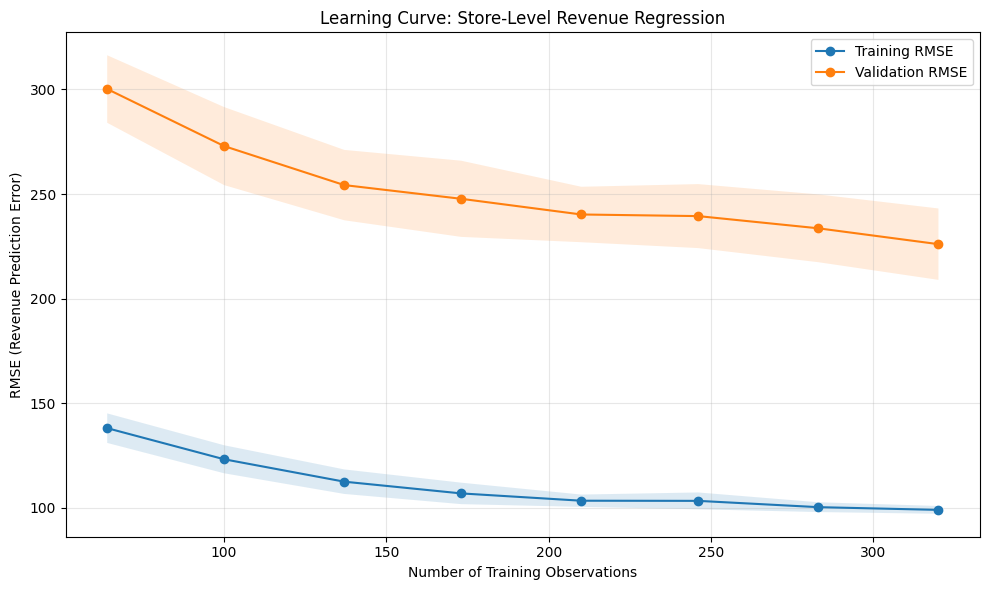

In [26]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import learning_curve, KFold
from sklearn.ensemble import RandomForestRegressor


def plot_learning_curve(X, y, model=None):
    """
    Plot training and validation RMSE against training set size.
    Shaded regions represent +/- 1 standard deviation across folds.
    """

    # Use an existing model if supplied; otherwise use Random Forest.
    if model is None:
        model = RandomForestRegressor(
            n_estimators=200,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )

    # Five shuffled folds provide different training/validation splits.
    cv = KFold(n_splits=5, shuffle=True, random_state=42)

    # Evaluate the model at increasing training sample sizes.
    train_sizes, train_scores, val_scores = learning_curve(
        estimator=model,
        X=X,
        y=y,
        train_sizes=np.linspace(0.2, 1.0, 8),
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
        shuffle=True,
        random_state=42
    )

    # Convert negative RMSE scores into positive errors.
    train_rmse = -train_scores
    val_rmse = -val_scores

    # Calculate average error and variability across folds.
    train_mean = np.mean(train_rmse, axis=1)
    train_std = np.std(train_rmse, axis=1)

    val_mean = np.mean(val_rmse, axis=1)
    val_std = np.std(val_rmse, axis=1)

    # Plot both learning curves on the same axis.
    plt.figure(figsize=(10, 6))

    plt.plot(
        train_sizes, train_mean,
        marker="o", label="Training RMSE"
    )

    plt.plot(
        train_sizes, val_mean,
        marker="o", label="Validation RMSE"
    )

    # Shaded bands show +/- one standard deviation across folds.
    plt.fill_between(
        train_sizes,
        train_mean - train_std,
        train_mean + train_std,
        alpha=0.15
    )

    plt.fill_between(
        train_sizes,
        val_mean - val_std,
        val_mean + val_std,
        alpha=0.15
    )

    plt.xlabel("Number of Training Observations")
    plt.ylabel("RMSE (Revenue Prediction Error)")
    plt.title("Learning Curve: Store-Level Revenue Regression")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Return results for further interpretation.
    return {
        "training_sizes": train_sizes,
        "training_rmse": train_mean,
        "validation_rmse": val_mean,
        "training_std": train_std,
        "validation_std": val_std
    }


# Run using your existing X and y.
results = plot_learning_curve(X, y)


The AI’s code used a random forest by default, because my prompt said “reuse my X and y” but never named a model. At 320 training rows the forest’s training RMSE is about 99 and its validation RMSE about 226. The gap of about 127 is large, and the validation curve is still falling slowly. Read on its own, this is a high-variance diagnosis: the gap points to variance, and the slow downward slope says more stores would help a little. A high-bias model would show both curves converging high with a small gap, and that is not what this plot shows.

It partly agrees and where it differs, the reason is the model. Step 3.1 found that training and held-out error stay close together up to about 65 fitted terms, with held-out error lowest at 14 terms. It rises sharply only at 285 terms. The sweep therefore says the chosen model sits near the best balance of bias and variance, while the forest curve says high variance. The two diagnoses differ because they describe different models. The sweep covers linear and polynomial regressions. The learning curve covers a random forest. Each is right about its own model, but the Phase 3 model is the one to use. The forest’s training RMSE of about 99 is below the noise floor of about 186 implied by my data-generating process. No honest model can beat that floor, so the forest is memorizing noise. This is also partly an artifact of scoring a forest on rows it was built from. The forest’s validation RMSE of about 226 is worse than the Phase 3 model’s held-out MSE of 37,928. The simpler model predicts new stores better. The Phase 3 model’s error is within about 5% of the noise floor in RMSE terms, so little room is left to improve. The two plots agree with each other on the main point of flexibility past the turn hurts. The forest sits on the high-variance side, as the 65- and 285-term models do in the sweep.

For the forest, more stores would help a little, but that model is worse than the one already chosen. For the chosen model, neither more stores nor better features from this set would pay much, because most of the remaining error is noise that grows with store size. The one route to lowering it is a predictor that explains that size-dependent noise. The learning curve and the sweep use different models and different splits, so I compare them as rough benchmarks, not exact numbers. The noise floor is known only because this is simulated data.

### Task 4.2: What "validated" meant (3 pts)

> **No AI on this task, and no transcript.** Here you are the reviewer.

The departing analyst's cell, copied from the brief. For (b), run it as it is with 300 pure-noise columns alone as `X` and your Phase 1 revenue as `y`.

In [27]:
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

X_scaled = StandardScaler().fit_transform(X)
X_sel = SelectKBest(f_regression, k=20).fit_transform(X_scaled, y)
scores = cross_val_score(LinearRegression(), X_sel, y, cv=5, scoring="r2")
print(f"Validated R^2: {scores.mean():.2f}")

Validated R^2: 0.93


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=20 is greater than n_features=11. All the features will be returned.
  warnings.warn(


In [28]:
noise_rng = np.random.default_rng(18)
X_noise = pd.DataFrame(noise_rng.normal(size=(N_STORES, 300)),
                       columns=[f"noise_{j}" for j in range(300)])   # 300 pure-noise columns
y_rev = store["revenue"]

# The analyst's cell: scale and select on ALL stores, then cross-validate only the regression
X_sel = SelectKBest(f_regression, k=20).fit_transform(StandardScaler().fit_transform(X_noise), y_rev)
all_rows = cross_val_score(LinearRegression(), X_sel, y_rev, cv=5, scoring="r2").mean()

# The same three steps refitted on each fold's training stores
pipe = Pipeline([("scale", StandardScaler()),
                 ("select", SelectKBest(f_regression, k=20)),
                 ("ols", LinearRegression())])
in_fold = cross_val_score(pipe, X_noise, y_rev, cv=5, scoring="r2").mean()

print(f"selected on all rows: R-squared {all_rows:.3f}, selected inside each fold: {in_fold:.3f} "
      f",gap {all_rows - in_fold:.3f}")

selected on all rows: R-squared 0.066, selected inside each fold: -0.280 | gap 0.346


(a) The inflating step is SelectKBest. It ranks columns by their relationship with y, so when it runs on all stores, the stores in each held-out fold have already helped choose the columns. Cross-validation then scores the model on rows that influenced its construction. The scaler is harmless for OLS with an intercept. It uses only X, never y, and standardizing is a shift and rescale of each column. OLS with an intercept gives identical predictions under such a transformation, so the fold scores are unchanged. It also does not change which columns SelectKBest ranks highest, because the F-statistic for a single column depends only on its correlation with y, which a shift and rescale leaves unchanged.

(b) I generated 300 columns of pure noise for the 400 stores and used them alone as X, with the Phase 1 revenue as y. None of them predicts revenue. The analyst’s cell gives R-squared 0.066, which their cell would print as 0.07 and a handover note would call “validated”. The same three steps inside a Pipeline, refitted on each fold’s training stores, give -0.280. The gap is 0.346. There is no real signal here, so the positive figure comes entirely from choosing the 20 columns that happened to correlate with revenue by chance, using rows the folds later treated as unseen. The honest score is negative: on new stores, this procedure predicts worse than simply using the average revenue.

(c) This is a special case of the Step 3.2 problem. In both, the held-out data influenced a choice that was then scored on those same rows, and the fix is the same, putting the choosing step inside the loop.

### Task 4.3: The handover note (3 pts)

The store revenue model uses OLS regression to predict monthly revenue ($ thousands) based on floor area, foot traffic, median income, and years open. Although the reported in-sample R² of 0.94 is reproducible at 0.93, this figure may overstate predictive performance. Previous validation was unreliable because feature selection occurred before cross-validation, introducing data leakage. Additionally, in-sample R² tends to increase as predictors are added, even when they are irrelevant. For example, using 300 random predictors produces an R² of 0.07 under the flawed approach, compared with -0.28 under proper validation. With appropriate cross-validation, the model achieves an RMSE of approximately 193 (range: 169–214), consistent with an RMSE of 195 on 120 untouched stores. However, aggregate accuracy masks meaningful differences in performance across store sizes. The linear specification does not adequately capture the concave relationship between floor area and revenue, resulting in overprediction of 1.4% for the largest store quintile and 2.5% for the smallest. Residual variability is also 2.65 times greater among the largest stores than the smallest. Furthermore, catchment_index exhibits substantial multicollinearity with foot traffic and income, reducing coefficient reliability. Recommended improvements include introducing a nonlinear floor-area term, removing catchment_index, and applying HC3 robust standard errors. Future model evaluation should use nested cross-validation, size-adjusted prediction intervals, and monthly residual monitoring by store-size segment.



## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; your prompt is in it as sent.
- [ ] Submit the Colab share link on Canvas (upload the `.ipynb` as a fallback).
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 4/Econ_3916_PS4.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.